# Transplanting the base model's plan into Qwen3-8B: replaying the Claim B decision

**Artifact:** iteration 5, Step 1 (experiment 24). **Models:** `Qwen/Qwen3-8B` (instruct, thinking off) and its base
model `Qwen/Qwen3-8B-Base`.

**Question.** Asked for a coding task, Qwen3-8B writes the same algorithm almost every time. For *top-k frequent* (T14)
it sorts by count; for *k-th smallest* (T03) it fully sorts. Given the *identical token ids*, the base model writes a
wider repertoire, such as a heap for T14 or quickselect for T03. Is that lost variety still recoverable at the model's
internal "plan site"?

**Intervention: a cross-model state transplant.** During the instruct model's prompt prefill, the task-specification
states at decoder blocks 12-23 are *set* to

$$h_{l,p} \leftarrow h^{\mathrm{instr}}_{l,p} + \lambda\,\big(h^{\mathrm{base}}_{l,p} - h^{\mathrm{instr}}_{l,p}\big),
\qquad \lambda \in \{0.25,\ 0.5,\ 1\}.$$

At $\lambda = 1$ the hooked blocks carry the base model's exact states. This arm is written `T(lambda)`.

**Claim B (pre-registered, primary).** On every decisive (BASE-DIVERSE) task, the transplant reopens the base model's
repertoire. To count, it must beat three controls on the *same* common-random-number (CRN) slots:

- `MR`: a norm-matched random displacement.
- `XT`: another task's base-minus-instruct shift, norm-matched.
- `MRP`: a pass-matched random push, used where MR breaks the model.

It must also land on the base model's own runner-up algorithm `r_t`.

**What this notebook runs.** `method.py` is a stage CLI. Stages 0-5 sample about 14,000 programs from the two 8B models
on a 24 GiB GPU (1.7 GPU-hours plus a 6.5 GB activation cache). Stage 8 is the CPU analysis that turns the labelled
programs into the verdict. This notebook replays stage 8 on the Stage-4 confirmation programs of two decisive tasks:
2 tasks x 5 prompt templates x 10 CRN slots = 100 slots, with every arm present on each slot. It uses the original
code:

- `src/analysis_b.py`: the frozen statistics and decision rules.
- `src/analysis_final.py`: `sel`, `cell` and `confirmation`.
- `audit/rederive.py`: an independent re-derivation and the arm-shuffle placebo.
- `src/figures5.py`: the original figures.

**The two tasks in `mini_demo_data.json`:**

- **T14 (top-k frequent):** the only task on which Claim B passes. T(1) writes a heap in 21 of 49 correct programs;
  the instruct twin writes none.
- **T03 (k-th smallest):** a matched-norm random push moves the algorithm *more* than the base state does.

**Full-artifact verdict:** Claim B is DISCONFIRMED. It passes on 1 of the 5 decisive tasks.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (version pinned in the artifact's pyproject.toml)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

# --- method.py ---
import argparse
import subprocess
import sys
import time
from pathlib import Path

# --- src/analysis_b.py, src/analysis_final.py, src/outputs5.py, audit/rederive.py ---
import json
import math
from collections import Counter, defaultdict
from typing import Any, Iterable

import numpy as np
from loguru import logger
from scipy import stats as sps
from scipy import stats

# --- src/figures5.py (its matplotlib.use("Agg") is dropped so that figures render inline) ---
import matplotlib
import matplotlib.pyplot as plt

# --- notebook additions ---
import types
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-5/experiment-24/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
# Until this version of the demo is published, GitHub may still serve an older copy of the file with a different
# layout; fall back to the local file when the loaded copy lacks the fields this notebook reads.
NEEDED = {"commit1", "commit2", "catalogues", "specificity_S1", "exp22_escape", "pipeline_results", "geometry"}
if not NEEDED <= set(data.get("metadata", {})) and Path("mini_demo_data.json").exists():
    print("The GitHub copy has an older layout; using local mini_demo_data.json")
    data = json.loads(Path("mini_demo_data.json").read_text())
ex = data["datasets"][0]["examples"]
print(data["datasets"][0]["dataset"], "-", len(ex), "CRN slots:", dict(Counter(e["metadata_task"] for e in ex)))
print("arm fields per slot:", sorted({k for e in ex for k in e if k == "output" or k.startswith("predict_")}))
print("\nOne slot (" + ex[0]["metadata_crn_key"] + "):", {k: v for k, v in ex[0].items() if k != "input"})
print("\nIts prompt (identical token ids for both models):\n" + ex[0]["input"])

The GitHub copy has an older layout; using local mini_demo_data.json
transplant_confirmation - 100 CRN slots: {'T14': 50, 'T03': 50}
arm fields per slot: ['output', 'predict_MR1_0', 'predict_MRP0_5', 'predict_T1_0', 'predict_XT1_0']

One slot (T14|W1|10): {'output': 'sort_by_count|pass', 'metadata_task': 'T14', 'metadata_template': 'W1', 'metadata_slot': 10, 'metadata_crn_key': 'T14|W1|10', 'metadata_model': 'Qwen/Qwen3-8B', 'predict_MR1_0': 'sort_by_count|pass', 'predict_MRP0_5': 'sort_by_count|pass', 'predict_T1_0': 'sort_by_count|pass', 'predict_XT1_0': 'sort_by_count|pass'}

Its prompt (identical token ids for both models):
Do not use picture for this task. . .

Task: write a Python function solve(nums, k) that returns the k values that occur most often in nums, as a list in any order. The argument nums is a list of integers with 1 <= len(nums) <= 10000 and every value between -10000 and 10000 inclusive; k is an integer between 1 and the number of distinct values in nums. The input

## Configuration

All tunable parameters of the replay are set here. The analysis is exact counting plus binomial tail probabilities,
so it runs in seconds even at the original values.

| Parameter | Meaning | Original value |
|---|---|---|
| `TASKS` | decisive tasks replayed from `mini_demo_data.json` | all 5 BASE-DIVERSE tasks (the demo file has T14 and T03) |
| `N_S2_SLOTS` | CRN slots per template on the fresh S2 set (j = 10, 11, ...); N = 5 x this per arm | 10 (N = 50) |
| `N_RAREFY` | subsamples for the rarefied Hill-1 diversity of every cell | 1000 |
| `DEPTH` | correct programs per rarefaction subsample | 25 |
| `N_PLACEBO_SHUFFLES` | within-slot arm swaps per task in the `audit/rederive.py` placebo | 200 |

In [5]:
# ---- demo configuration: every tunable parameter of the replay ----
# Decisive tasks to replay. Original: all 5 BASE-DIVERSE tasks (T03, T2, T10, T1, T14);
# mini_demo_data.json carries T14 and T03.
TASKS = ["T14", "T03"]
# CRN slots per template on the fresh S2 set (j = 10, 11, ...): N = 5 templates x N_S2_SLOTS programs per arm.
N_S2_SLOTS = 10             # original: 10 (N = 50)
# Rarefied Hill-1 diversity of each cell: N_RAREFY subsamples of DEPTH correct programs.
N_RAREFY = 1000             # original: 1000
DEPTH = 25                  # original: 25
# Arm-shuffle placebo of audit/rederive.py: random within-slot swaps per decisive task.
N_PLACEBO_SHUFFLES = 200    # original: 200

## 1. The stage CLI (`method.py`)

`method.py` is the artifact's entry point. It runs the pipeline stage by stage, and every stage is resumable.

| Stage | What runs | Hardware |
|---|---|---|
| 0 | prompts, provenance and labeller checks, CPU unit tests | CPU |
| 1 | base repertoire: Qwen3-8B-Base writes 2,000 chat-template and 1,500 plain-completion programs (vLLM) | GPU |
| 2 | instruct twin, engine check, the instruct model's clean prefill states, COMMIT #0 | GPU |
| 3 | judge audit of the base labels; COMMIT #1 (`default_t`, `beta_t`, `r_t`, strata, plans) | CPU + LLM judges |
| 4 | the base model's clean prefill states; the reverse interchange (instruct states into the base model) | GPU |
| 5 | Stage-3 selection on S1, COMMIT #2 (`lambda*`), the Claim D pushes, Stage-4 confirmation on S2 | GPU |
| 8 | analyses, geometry, novelty audit, figures, `method_out.json`, independent re-derivation | CPU |

A label worker (`src/labels5.py --follow`) runs beside stages 1-5. For each program it runs the hidden tests and
labels the algorithm: a runtime tracer first, the AST second, and a blind LLM judge only when the two disagree.

The cell below is `method.py` as shipped, with two notebook fixes:

- `ROOT` uses the working directory, because a notebook has no `__file__`.
- `main()` is not called.

Stages 0-5 need the `src/` tree, two virtual environments, both 8B checkpoints and an RTX-4090-class GPU. The rest of
this notebook replays the CPU part of `--stage 8` (`src/analysis_final.py`, then `src/figures5.py`) on the saved
Stage-4 programs.

In [6]:
"""Stage CLI of the iteration-5 'transplanting the base model's plan' artifact (resumable: every stage skips the
rows / files it has already written; GPU stages hold one 8B model at a time).

  .venv/bin/python method.py --stage 0   prompts (src/prompts5.py), Stage-0 checks (src/s0.py), CPU unit tests
  .venv/bin/python method.py --stage 1   base repertoire with vLLM (src/base_vllm.py, .venv_vllm) + label worker
  .venv/bin/python method.py --stage 2   instruct engine check / twin / states (src/gpu5.py instr1), COMMIT #0
  .venv/bin/python method.py --stage 3   base audit (src/audit5.py base), COMMIT #1 (src/commits5.py 1)
  .venv/bin/python method.py --stage 4   base states + Stage 6 reverse interchange (src/gpu5.py base1)
  .venv/bin/python method.py --stage 5   Stage 3 selection, Stage 5 push, COMMIT #2, Stage 4 confirmation
                                         (src/gpu5.py instr2)
  .venv/bin/python method.py --stage 8   analyses, geometry, novelty audit, figures, outputs, re-derivation
The label worker (src/labels5.py --follow) must run beside stages 1-5; `--stage all` runs everything in order.
"""

ROOT = Path.cwd()  # original: Path(__file__).resolve().parent (a notebook has no __file__)
PY = str(ROOT / ".venv" / "bin" / "python")
PYV = str(ROOT / ".venv_vllm" / "bin" / "python")
SRC = ROOT / "src"


def run(cmd: list[str]) -> None:
    print(f"$ {' '.join(cmd)}", flush=True)
    t0 = time.time()
    subprocess.run(cmd, cwd=SRC, check=True)
    print(f"  done in {time.time() - t0:.0f}s", flush=True)


def start_labeller() -> subprocess.Popen:
    return subprocess.Popen([PY, "labels5.py", "--follow"], cwd=SRC,
                            stdout=open(ROOT / "logs" / "labels5.out", "a"), stderr=subprocess.STDOUT)


def main() -> None:
    ap = argparse.ArgumentParser()
    ap.add_argument("--stage", default="all", choices=["0", "1", "2", "3", "4", "5", "8", "all"])
    a = ap.parse_args()
    st = a.stage
    lab = None
    if st in ("1", "2", "3", "4", "5", "all"):
        lab = start_labeller()
    try:
        if st in ("0", "all"):
            run([PY, "prompts5.py"])
            run([PY, "s0.py"])
            run([PY, str(ROOT / "tests" / "test_cpu.py")])
        if st in ("1", "all"):
            run([PYV, "base_vllm.py", "--stage", "all"])
        if st in ("2", "all"):
            run([PY, "gpu5.py", "instr1"])
            run([PY, "commits5.py", "0"])
        if st in ("3", "all"):
            run([PY, "audit5.py", "base"])
            run([PY, "commits5.py", "1"])
        if st in ("4", "all"):
            run([PY, "gpu5.py", "base1", "--wait-min", "5"])
        if st in ("5", "all"):
            run([PY, "gpu5.py", "instr2", "--wait-min", "40"])
        if st in ("8", "all"):
            (ROOT / "data" / "labels_stop.flag").write_text("stop")
            run([PY, "analysis_final.py"])
            run([PY, "geometry5.py", "all"])
            run([PY, "audit5.py", "novelty"])
            run([PY, "analysis_final.py"])
            run([PY, "figures5.py"])
            run([PY, "outputs5.py"])
            run([PY, str(ROOT / "audit" / "rederive.py")])
    finally:
        if lab is not None and st != "all":
            lab.terminate()


# Not executed in this notebook: the GPU stages need the full repository, two 8B models and a 24 GiB GPU.
# if __name__ == "__main__":
#     sys.exit(main())
print("method.py loaded (not run). Replaying the CPU part of `--stage 8` below.")

method.py loaded (not run). Replaying the CPU part of `--stage 8` below.


## 2. Constants from `src/cfg.py`

The slot sets fix which **common-random-number (CRN) slots** belong to each stage. A CRN slot is one
(task, template W1-W5, slot j) triple with its own pre-drawn stream of token uniforms. Every arm decodes from the same
stream on the same slot, so the programs of two arms on one slot form a matched pair. At lambda = 0 the transplant
reproduces the twin token for token (unit test U2, 20/20).

- S1 (j = 0-9) selects `lambda*` (Stage 3).
- S2 (j = 10-19) holds fresh slots for the confirmatory test (Stage 4).

`S2_SLOTS_50` is tied to `N_S2_SLOTS` from the config cell. `catalogue()` returns each task's frozen list of known
algorithms. The lists come from the bench `spec.json` files and are copied into `mini_demo_data.json`.

In [7]:
# ---- src/cfg.py: the constants the Stage-8 code below reads ----
PATH_TASKS = ("T1", "T2")
PATH_CATALOGUE = {"T1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
                  "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}
TEMPLATE_IDS = ["W1", "W2", "W3", "W4", "W5"]
S1_SLOTS = list(range(10))              # selection slots j = 0..9 (N = 50 per task)
S2_SLOTS_100 = list(range(10, 30))      # confirmation slots (N = 100)
S2_SLOTS_50 = list(range(10, 10 + N_S2_SLOTS))  # confirmation slots (N = 50); original: list(range(10, 20))
LAMBDAS = (0.25, 0.5, 1.0)
# DEPTH = 25 and N_RAREFY = 1000 are set in the config cell


def catalogue(task: str) -> list[str]:
    """Catalogue modes of a task (bench spec.json; exp8 suite CATALOGUE for T1/T2)."""
    if task in PATH_TASKS:
        return list(PATH_CATALOGUE[task])
    # original: [c["mode"] for c in read_json(<bench dir of task> / "spec.json")["catalogue"]]
    return list(data["metadata"]["catalogues"][task])


for t in TASKS:
    print(f"{t} catalogue: {catalogue(t)}")
print("S2 slots used:", S2_SLOTS_50)

T14 catalogue: ['sort_by_count', 'heap', 'bucket_sort', 'quickselect_counts']
T03 catalogue: ['full_sort', 'size_k_heap', 'heapify_pop', 'quickselect', 'median_of_medians', 'counting_sort']
S2 slots used: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


## 3. The frozen statistics (`src/analysis_b.py`)

This module's sha256 was hash-committed in COMMIT #0, before any transplant was sampled. It is copied here unchanged,
in four parts.

**3a. Row helpers and diversity.**

- A program is **correct** if it passed every hidden test and code was extracted.
- Its **label** is the algorithm the labeller assigned.
- `y_off` is the per-slot outcome of the confirmatory test: 1 if the program is correct *and* uses a catalogue
  algorithm other than the instruct model's default `default_t`.
- `off_share` is the off-default share among correct programs.
- Hill-1 is exp(Shannon entropy) of the label distribution. The rarefied version averages it over subsamples of
  `DEPTH` programs.

In [8]:
"""Frozen analysis code (sha256 committed in COMMIT #0): statistics and the pre-registered decision rules for
Claim B (transplant reopens the base repertoire), Claim D (de-sharpening push) and the reverse interchange.

Definitions (also restated in predictions/commit0.json):
- correct(r)       := passed every hidden test AND a program was extracted (label != 'invalid').
- catalogue label  := a label in the task's catalogue; 'other' and 'invalid' are never catalogue labels.
- off-default share (among correct) := n(correct, catalogue label != default_t) / n(correct); 'other' stays in the
                      denominator only.
- y(slot)          := 1[correct AND catalogue label != default_t] (per CRN slot; the McNemar outcome).
- default_t        := modal correct label of the S1 twin if its share among correct >= 0.6, else None.
- beta_t           := off-default share of the BASE_CHAT programs w.r.t. default_t (fewer than 20 correct even after
                      the top-up -> the same share over parseable attempts, flagged ATTEMPT).
- r_t              := the most frequent correct non-default catalogue label of BASE_CHAT (ties: more attempts, then
                      alphabetical).
- strata           := BASE-DIVERSE beta >= 0.20; BASE-COLLAPSED beta < 0.05; INTERMEDIATE otherwise.
Tests: one-sided exact McNemar = binomial(b, b + c, 1/2) upper tail on the discordant pairs of y; Holm over the
decisive family; Wilson intervals for shares, Newcombe (hybrid score) intervals for differences.
"""

NON_CATALOGUE = {"other", "invalid", None, "unknown", "unresolved", "no_code"}


# ------------------------------------------------------------------------------------------------ row helpers
def is_correct(r: dict[str, Any]) -> bool:
    return bool(r.get("passed")) and r.get("label") not in ("invalid", None)


def is_valid(r: dict[str, Any]) -> bool:
    return r.get("label") not in ("invalid", None)


def cat_label(r: dict[str, Any], cat: Iterable[str]) -> str | None:
    lab = r.get("label")
    return lab if lab in set(cat) else None


def y_off(r: dict[str, Any], default: str | None, cat: Iterable[str]) -> int:
    lab = cat_label(r, cat)
    return int(is_correct(r) and lab is not None and default is not None and lab != default)


def z_def(r: dict[str, Any], default: str | None) -> int:
    return int(is_correct(r) and default is not None and r.get("label") == default)


def composition(rows: list[dict[str, Any]], correct_only: bool = True) -> dict[str, int]:
    c = Counter(r.get("label") for r in rows if (is_correct(r) if correct_only else is_valid(r)))
    return dict(sorted(c.items(), key=lambda kv: (-kv[1], str(kv[0]))))


def off_share(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str],
              attempts: bool = False) -> tuple[float | None, int, int]:
    """(share, k, n): among correct programs (attempts=True: among parseable attempts)."""
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    cs = set(cat)
    k = sum(1 for r in pool if r.get("label") in cs and r.get("label") != default)
    return (k / len(pool) if pool else None), k, len(pool)


def default_share(rows: list[dict[str, Any]], default: str | None, attempts: bool = False
                  ) -> tuple[float | None, int, int]:
    pool = [r for r in rows if (is_valid(r) if attempts else is_correct(r))]
    k = sum(1 for r in pool if r.get("label") == default)
    return (k / len(pool) if pool else None), k, len(pool)


def pass_rate(rows: list[dict[str, Any]]) -> tuple[float | None, int, int]:
    n = len(rows)
    k = sum(is_correct(r) for r in rows)
    return (k / n if n else None), k, n


# ------------------------------------------------------------------------------------------------ diversity
def hill1(counts: dict[str, int] | Counter) -> float | None:
    v = np.array([c for c in counts.values() if c > 0], dtype=float)
    if v.sum() == 0:
        return None
    p = v / v.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def rarefied_hill1(labels: list[str], depth: int = 25, n_sub: int = 1000, seed: int = 20261021
                   ) -> dict[str, Any]:
    """Mean Hill-1 over n_sub subsamples of `depth` correct programs without replacement (fewer: all, flagged)."""
    n = len(labels)
    if n == 0:
        return {"hill1": None, "n": 0, "flag_below_depth": True}
    if n <= depth:
        return {"hill1": hill1(Counter(labels)), "n": n, "flag_below_depth": n < depth}
    rng = np.random.default_rng(seed)
    arr = np.array(labels, dtype=object)
    vals = []
    for _ in range(n_sub):
        sub = arr[rng.choice(n, size=depth, replace=False)]
        vals.append(hill1(Counter(sub.tolist())))
    return {"hill1": float(np.mean(vals)), "n": n, "flag_below_depth": False}

**3b. Intervals and tests.**

- **Wilson intervals** for shares, and **Newcombe** hybrid-score intervals for differences.
- The **one-sided exact McNemar test** on the discordant CRN pairs:
  - b = slots where the transplant is off-default-correct and the control is not;
  - c = the reverse;
  - p = the upper tail of Binomial(b + c, 1/2) at b.
- **Holm** step-down adjustment over the decisive family.
- `pair_rows` matches two arms on the same (template, slot).
- `template_robustness` counts the templates on which the transplant beats a control.

In [9]:
# ------------------------------------------------------------------------------------------------ intervals
def wilson(k: int, n: int, z: float = 1.959963984540054) -> tuple[float | None, float | None]:
    if n == 0:
        return None, None
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return max(0.0, c - h), min(1.0, c + h)


def newcombe(k1: int, n1: int, k2: int, n2: int) -> dict[str, float | None]:
    """Newcombe (1998) method 10 hybrid score interval for p1 - p2 (independent proportions)."""
    if n1 == 0 or n2 == 0:
        return {"diff": None, "lo": None, "hi": None}
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    lo = d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2)
    hi = d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2)
    return {"diff": d, "lo": lo, "hi": hi}


# ------------------------------------------------------------------------------------------------ tests
def mcnemar_exact(a: list[int], b: list[int]) -> dict[str, Any]:
    """Paired binary outcomes (same CRN slots): H1 one-sided a > b. b_ = #(a=1, b=0), c_ = #(a=0, b=1)."""
    assert len(a) == len(b)
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    n = b_ + c_
    if n == 0:
        return {"b": 0, "c": 0, "n_pairs": len(a), "p_one": 1.0, "p_two": 1.0}
    p_one = float(sps.binom.sf(b_ - 1, n, 0.5))
    p_two = float(min(1.0, 2 * min(sps.binom.cdf(b_, n, 0.5), sps.binom.sf(b_ - 1, n, 0.5))))
    return {"b": b_, "c": c_, "n_pairs": len(a), "p_one": p_one, "p_two": p_two}


def binom_upper(k: int, n: int, p0: float) -> float:
    if n == 0:
        return 1.0
    return float(sps.binom.sf(k - 1, n, min(max(p0, 1e-12), 1 - 1e-12)))


def holm(pvals: dict[str, float]) -> dict[str, float]:
    keys = sorted(pvals, key=lambda k: pvals[k])
    m = len(keys)
    out: dict[str, float] = {}
    run = 0.0
    for i, k in enumerate(keys):
        adj = min(1.0, (m - i) * pvals[k])
        run = max(run, adj)
        out[k] = run
    return out


def pair_rows(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]]) -> list[tuple[dict, dict]]:
    """Pair rows of two arms on the same (template, slot)."""
    bm = {(r["template"], int(r["slot"])): r for r in b_rows}
    out = []
    for r in a_rows:
        k = (r["template"], int(r["slot"]))
        if k in bm:
            out.append((r, bm[k]))
    return sorted(out, key=lambda p: (p[0]["template"], int(p[0]["slot"])))


def template_robustness(a_rows: list[dict[str, Any]], b_rows: list[dict[str, Any]], default: str | None,
                        cat: Iterable[str]) -> dict[str, Any]:
    cat = list(cat)
    out = {}
    n_gt = 0
    for w in sorted({r["template"] for r in a_rows}):
        ya = [y_off(r, default, cat) for r in a_rows if r["template"] == w]
        yb = [y_off(r, default, cat) for r in b_rows if r["template"] == w]
        ra = float(np.mean(ya)) if ya else None
        rb = float(np.mean(yb)) if yb else None
        out[w] = {"y_rate_arm": ra, "y_rate_control": rb}
        n_gt += int(ra is not None and rb is not None and ra > rb)
    return {"by_template": out, "n_templates_arm_gt_control": n_gt, "n_templates": len(out)}

**3c. Base repertoire (COMMIT #1).** These functions turned the base model's programs into the pre-registered
constants of each task:

- `default_t`: the instruct twin's modal correct label, if its share is at least 0.6.
- `beta_t`: the base model's off-default share.
- `r_t`: the base model's most frequent correct non-default algorithm (its runner-up).
- The stratum: BASE-DIVERSE if beta >= 0.20, BASE-COLLAPSED if beta < 0.05, INTERMEDIATE otherwise.

They need the 2,000 base-model programs, which are a different dataset. The demo does not re-run them; it reads
their committed output from COMMIT #1.

In [10]:
# ------------------------------------------------------------------------------------------------ base repertoire
def default_from_twin(rows: list[dict[str, Any]], min_share: float = 0.6) -> tuple[str | None, float | None]:
    comp = composition(rows)
    n = sum(comp.values())
    if n == 0:
        return None, None
    lab, k = max(comp.items(), key=lambda kv: (kv[1], str(kv[0]) == "other" and -1 or 0, str(kv[0])))
    share = k / n
    if lab in NON_CATALOGUE or share < min_share:
        return None, share
    return lab, share


def runner_up(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> str | None:
    cs = set(cat)
    corr = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in cs and r["label"] != default)
    if not corr:
        return None
    att = Counter(r["label"] for r in rows if is_valid(r) and r.get("label") in cs)
    return sorted(corr, key=lambda m: (-corr[m], -att.get(m, 0), m))[0]


def stratum(beta: float | None, diverse: float = 0.20, collapsed: float = 0.05) -> str | None:
    if beta is None:
        return None
    if beta >= diverse:
        return "BASE-DIVERSE"
    if beta < collapsed:
        return "BASE-COLLAPSED"
    return "INTERMEDIATE"


def base_beta(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], min_correct: int = 20
              ) -> dict[str, Any]:
    s, k, n = off_share(rows, default, cat)
    flag = n < min_correct
    if flag:
        s2, k2, n2 = off_share(rows, default, cat, attempts=True)
        return {"beta": s2, "k": k2, "n": n2, "basis": "ATTEMPT", "n_correct": n, "beta_correct_only": s}
    return {"beta": s, "k": k, "n": n, "basis": "CORRECT", "n_correct": n}


def beta_bootstrap(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str], B: int = 2000,
                   seed: int = 20261021, min_correct: int = 20) -> dict[str, Any]:
    """Template-cluster bootstrap: resample the 5 templates with replacement (all rows of a template together)."""
    by_w: dict[str, list[dict[str, Any]]] = {}
    for r in rows:
        by_w.setdefault(r["template"], []).append(r)
    ws = sorted(by_w)
    rng = np.random.default_rng(seed)
    point = base_beta(rows, default, cat, min_correct)
    st0 = stratum(point["beta"])
    vals, same = [], 0
    for _ in range(B):
        pick = rng.choice(len(ws), size=len(ws), replace=True)
        rr = [r for i in pick for r in by_w[ws[i]]]
        b = base_beta(rr, default, cat, min_correct)["beta"]
        if b is None:
            continue
        vals.append(b)
        same += int(stratum(b) == st0)
    if not vals:
        return {"ci": [None, None], "stability": None, "n_boot": 0}
    return {"ci": [float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))],
            "stability": same / len(vals), "n_boot": len(vals)}


def smoothed_landing(rows: list[dict[str, Any]], default: str | None, cat: Iterable[str]) -> dict[str, float]:
    modes = [m for m in cat if m != default]
    c = Counter(r["label"] for r in rows if is_correct(r) and r.get("label") in set(modes))
    tot = sum(c.values()) + 0.5 * len(modes)
    return {m: (c.get(m, 0) + 0.5) / tot for m in modes} if modes else {}


def derangement(tasks: list[str], seed: int) -> dict[str, str]:
    """Seeded random derangement (no fixed points) by rejection sampling of permutations."""
    rng = np.random.default_rng(seed)
    ts = sorted(tasks)
    if len(ts) < 2:
        return {}
    while True:
        perm = rng.permutation(len(ts))
        if all(perm[i] != i for i in range(len(ts))):
            return {ts[i]: ts[int(perm[i])] for i in range(len(ts))}

**3d. Decision rules.**

`claim_b_task` checks four conditions on each decisive task:

1. **(i)** pass(T) >= 0.8 x pass(twin).
2. **(ii)** off-default share of T >= 0.5 x `beta_t`.
3. **(iii)** T beats MR and XT (and MRP, if MR broke the model) at Holm p < 0.05.
4. **(iv)** T's modal correct non-default algorithm is the base runner-up `r_t`.

`claim_b_verdict` then decides:

- **CONFIRMED** if at least ceil(2 n_div / 3) tasks PASS and the S1 specificity check holds.
- **DISCONFIRMED** if every decisive task keeps a valid pass rate and (iii) fails on more than a third of them.
- **PARTIAL** otherwise.

The Claim D and reverse-interchange rules are included for completeness. The last line exposes the module as `A`, the
name `analysis_final.py` uses for it (`import analysis_b as A`).

In [11]:
# ------------------------------------------------------------------------------------------------ rules
def select_lambda(cells: dict[float, dict[str, Any]], twin_pass: float, frac: float = 0.8) -> float | None:
    """cells[lam] = {'pass': p, 'off_share': s}; lam* = argmax off_share among lam with pass >= frac * twin_pass;
    ties -> the smaller lambda; none -> None (UNTESTED)."""
    ok = [(lam, c) for lam, c in cells.items() if c.get("pass") is not None and c["pass"] >= frac * twin_pass
          and c.get("off_share") is not None]
    if not ok:
        return None
    best = max(c["off_share"] for _, c in ok)
    return min(lam for lam, c in ok if c["off_share"] == best)


def broken(pass_arm: float | None, twin_pass: float, frac: float = 0.8) -> bool:
    return pass_arm is None or pass_arm < frac * twin_pass


def claim_b_task(*, beta: float, r_t: str | None, pass_T: float, pass_twin: float, offshare_T: float | None,
                 p_holm: dict[str, float], mr_broke: bool, modal_T: str | None) -> dict[str, Any]:
    c1 = pass_T >= 0.8 * pass_twin
    c2 = offshare_T is not None and offshare_T >= 0.5 * beta
    need = ["MR", "XT"] + (["MRp"] if mr_broke else [])
    c3 = all(p_holm.get(k, 1.0) < 0.05 for k in need)
    c3_mr = p_holm.get("MR", 1.0) < 0.05 and (not mr_broke or p_holm.get("MRp", 1.0) < 0.05)
    c3_xt = p_holm.get("XT", 1.0) < 0.05
    c4 = modal_T is not None and modal_T == r_t
    return {"i_pass": c1, "ii_share": c2, "iii_controls": c3, "iii_vs_MR": c3_mr, "iii_vs_XT": c3_xt,
            "iv_landing": c4, "PASS": bool(c1 and c2 and c3 and c4), "controls_required": need}


def claim_b_verdict(task_res: dict[str, dict[str, Any]], n_div: int, specificity: bool, valid: bool
                    ) -> dict[str, Any]:
    if not valid:
        return {"verdict": "UNTESTED", "reason": "validity gate failed"}
    if n_div < 3:
        return {"verdict": "DESCRIPTIVE", "reason": f"only {n_div} BASE-DIVERSE tasks with a default (< 3)"}
    dec = {t: r for t, r in task_res.items() if r.get("decisive")}
    n_pass = sum(1 for r in dec.values() if r["rule"]["PASS"])
    need = math.ceil(2 * n_div / 3)
    n_iii_fail = sum(1 for r in dec.values() if not r["rule"]["iii_controls"])
    pass_ok = all(r["rule"]["i_pass"] for r in dec.values())
    if n_pass >= need and specificity:
        v = "CONFIRMED"
    elif pass_ok and n_iii_fail > len(dec) / 3:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    branches = []
    if v == "PARTIAL":
        if any(r["rule"]["iii_vs_MR"] and not r["rule"]["iii_vs_XT"] for r in dec.values()):
            branches.append("beats MR but not XT -> a generic base shift reopens")
        if not specificity:
            branches.append("specificity failed (READ moves or collapsed tasks move)")
        if any(r["rule"]["iii_controls"] and not r["rule"]["iv_landing"] for r in dec.values()):
            branches.append("lands off r_t -> reopens, but not the base runner-up")
    return {"verdict": v, "n_decisive": len(dec), "n_pass": n_pass, "needed": need, "n_iii_fail": n_iii_fail,
            "specificity": specificity, "branches": branches}


def escapes(*, k_off: int, n: int, off_share_arm: float | None, off_share_twin: float, pass_arm: float,
            pass_twin: float, twin_k: int, twin_n: int) -> dict[str, Any]:
    """Claim D cell rule: off-default share (among correct) >= twin + 0.20 AND pass >= 0.8 x twin AND one-sided exact
    binomial p < 0.05 of k_off (correct off-default slots out of n) against the twin's smoothed per-slot rate
    p0 = (twin_k + 0.5) / (twin_n + 1)."""
    p0 = (twin_k + 0.5) / (twin_n + 1)
    p = binom_upper(k_off, n, p0)
    ok = (off_share_arm is not None and off_share_arm >= off_share_twin + 0.20 and pass_arm >= 0.8 * pass_twin
          and p < 0.05)
    return {"escapes": bool(ok), "p_binom": p, "p0": p0}


def claim_d_task(a_ds: float | None, a_iso: float | None, ds_landing: str | None, r_t: str | None) -> dict[str, Any]:
    if a_ds is None:
        return {"PASS": False, "reason": "DS never escapes"}
    if a_iso is None:  # ISO censored above 2
        ok = a_ds <= 1.0
    else:
        ok = a_ds <= 0.5 * a_iso
    return {"PASS": bool(ok and ds_landing == r_t), "dose_ok": bool(ok), "landing_ok": ds_landing == r_t}


def claim_d_verdict(task_res: dict[str, dict[str, Any]]) -> dict[str, Any]:
    if not task_res:
        return {"verdict": "UNTESTED"}
    n = len(task_res)
    n_pass = sum(1 for r in task_res.values() if r["rule"]["PASS"])
    better = sum(1 for r in task_res.values()
                 if r["a_ds"] is not None and (r["a_iso"] is None or r["a_ds"] < r["a_iso"]))
    if n_pass >= math.ceil(2 * n / 3):
        v = "CONFIRMED"
    elif better == 0:
        v = "DISCONFIRMED"
    else:
        v = "PARTIAL"
    return {"verdict": v, "n_tasks": n, "n_pass": n_pass, "n_ds_earlier_than_iso": better}


def reverse_prediction(share_rt: float | None, share_btwin: float | None, share_instr_twin: float | None
                       ) -> dict[str, Any]:
    if None in (share_rt, share_btwin, share_instr_twin):
        return {"met": None}
    need = share_btwin + 0.5 * (share_instr_twin - share_btwin)
    return {"met": bool(share_rt >= need), "threshold": need, "rise": share_rt - share_btwin,
            "predicted_min_rise": 0.5 * (share_instr_twin - share_btwin)}


def jsd(p: dict[str, int], q: dict[str, int]) -> float:
    keys = sorted(set(p) | set(q), key=str)
    a = np.array([p.get(k, 0) for k in keys], float)
    b = np.array([q.get(k, 0) for k in keys], float)
    if a.sum() == 0 or b.sum() == 0:
        return float("nan")
    a, b = a / a.sum(), b / b.sum()
    m = (a + b) / 2

    def kl(x, y):
        nz = x > 0
        return float((x[nz] * np.log2(x[nz] / y[nz])).sum())
    return 0.5 * kl(a, m) + 0.5 * kl(b, m)


def log_score(landings: list[str], dist: dict[str, float]) -> float | None:
    if not landings or not dist:
        return None
    return float(np.mean([math.log(max(dist.get(l, 0.0), 1e-12)) for l in landings]))


# analysis_final.py imports this module as `A` (`import analysis_b as A`); bundle the functions above the same way
A = types.SimpleNamespace(NON_CATALOGUE=NON_CATALOGUE, **{name: globals()[name] for name in [
    "is_correct", "is_valid", "cat_label", "y_off", "z_def", "composition", "off_share", "default_share",
    "pass_rate", "hill1", "rarefied_hill1", "wilson", "newcombe", "mcnemar_exact", "binom_upper", "holm",
    "pair_rows", "template_robustness", "default_from_twin", "runner_up", "stratum", "base_beta", "beta_bootstrap",
    "smoothed_landing", "derangement", "select_lambda", "broken", "claim_b_task", "claim_b_verdict", "escapes",
    "claim_d_task", "claim_d_verdict", "reverse_prediction", "jsd", "log_score"]})
print(f"analysis_b: {len(vars(A))} frozen definitions")

analysis_b: 36 frozen definitions


## 4. From CRN-slot examples back to labelled programs

`method_out.json` stores one example per CRN slot:

- `output` is the unhooked instruct twin's program, as `label|pass`.
- `predict_<arm>` is each arm's program on the same slot, in the same format.

`src/outputs5.py` writes these fields with `lp()` and `safe()`, shown below. The adapter inverts them into one
labelled row per (task, arm, template, slot): the shape of `data/labels.jsonl` that `analysis_final.py` reads. The arm
names come from the committed Stage-4 plan in COMMIT #2.

The cell also prints the committed constants of the demo tasks:

- from COMMIT #1: `default_t`, `beta_t`, the stratum and the base runner-up `r_t`;
- from COMMIT #2: `lambda*`, and whether MR at `lambda*` broke the pass rate. If it did, the pass-matched MRP at
  `lambda'` joins the controls.

In [12]:
def lp(r: dict[str, Any] | None) -> str:
    if r is None:
        return "NA"
    return f"{r.get('label')}|{'pass' if r.get('passed') else 'fail'}"


def safe(a: str) -> str:
    return "predict_" + a.replace(".", "_").replace("-", "_")



# ---- notebook adapter: invert lp() / safe() into one labelled row per (task, arm, template, slot) ----
c1 = data["metadata"]["commit1"]        # COMMIT #1 = predictions/commit1.json
c2_full = data["metadata"]["commit2"]   # COMMIT #2 = predictions/commit2.json
ARM_OF = {safe(a): a for cells in c2_full["stage4_plan"].values() for a, _ in cells}
ARM_OF["output"] = "TWIN"               # the reference arm of transplant_confirmation: the unhooked instruct twin


def unlp(s: str) -> tuple[str | None, bool]:
    lab, res = s.rsplit("|", 1)
    return (None if lab == "None" else lab), res == "pass"


labs = []
for e in data["datasets"][0]["examples"]:
    if e["metadata_task"] not in TASKS or e["metadata_slot"] not in S2_SLOTS_50:
        continue
    for key, arm in ARM_OF.items():
        if key in e:
            lab, passed = unlp(e[key])
            labs.append({"task": e["metadata_task"], "arm": arm, "template": e["metadata_template"],
                         "slot": e["metadata_slot"], "label": lab, "passed": passed,
                         "model": e["metadata_model"], "crn_key": e["metadata_crn_key"]})
print(len(labs), "labelled programs:", dict(Counter(f"{r['task']}|{r['arm']}" for r in labs)))

for t in TASKS:
    p, s = c1["per_task"][t], c2_full["selection"][t]
    print(f"\n{t}: default_t = {p['default']}, beta_t = {p['beta']:.2f} ({p['beta_basis']}), {p['stratum']}, "
          f"r_t = {p['r_t']}; base-model correct programs: {p['base_chat']['composition_correct']}")
    print(f"    COMMIT #2: lambda* = {s['lambda_star']}, MR broken at lambda* = {s['MR_broken_at_lambda_star']}, "
          f"lambda' = {s['lambda_prime']}; Stage-4 arms: {[a for a, _ in c2_full['stage4_plan'][t]]}")

450 labelled programs: {'T14|T1.0': 50, 'T14|MR1.0': 50, 'T14|XT1.0': 50, 'T14|MRP0.5': 50, 'T14|TWIN': 50, 'T03|T1.0': 50, 'T03|MR1.0': 50, 'T03|XT1.0': 50, 'T03|TWIN': 50}

T14: default_t = sort_by_count, beta_t = 0.35 (CORRECT), BASE-DIVERSE, r_t = heap; base-model correct programs: {'sort_by_count': 20, 'heap': 11}
    COMMIT #2: lambda* = 1.0, MR broken at lambda* = True, lambda' = 0.5; Stage-4 arms: ['T1.0', 'MR1.0', 'XT1.0', 'MRP0.5']

T03: default_t = full_sort, beta_t = 0.43 (CORRECT), BASE-DIVERSE, r_t = quickselect; base-model correct programs: {'full_sort': 26, 'quickselect': 13, 'size_k_heap': 4, 'heapify_pop': 3, 'other': 1}
    COMMIT #2: lambda* = 1.0, MR broken at lambda* = False, lambda' = None; Stage-4 arms: ['T1.0', 'MR1.0', 'XT1.0']


## 5. Per-cell summaries (`analysis_final.sel`, `analysis_final.cell`)

- `sel` picks the rows of one (task, arm) on a slot set.
- `cell` summarises them: pass rate, off-default share, y-rate, compositions, rarefied Hill-1 and the modal correct
  non-default algorithm.

One edit: the hard-coded 1000 rarefaction subsamples now come from `N_RAREFY`.

In [13]:
def sel(labs: list[dict[str, Any]], task: str, arm: str, slots: set[int] | list[int] | None = None,
        model: str | None = None) -> list[dict[str, Any]]:
    s = set(slots) if slots is not None else None
    return [r for r in labs if r["task"] == task and r["arm"] == arm and (s is None or int(r["slot"]) in s)
            and (model is None or r.get("model") == model)]


def cell(rows: list[dict[str, Any]], d: str | None, cat: list[str]) -> dict[str, Any]:
    n = len(rows)
    pr, kp, _ = A.pass_rate(rows)
    sh, ko, nc = A.off_share(rows, d, cat)
    y = [A.y_off(r, d, cat) for r in rows]
    comp = A.composition(rows)
    corr = [r["label"] for r in rows if A.is_correct(r)]
    return {"n": n, "pass": pr, "k_pass": kp, "pass_wilson": A.wilson(kp, n), "n_correct": nc, "off_share": sh,
            "k_off": ko, "off_wilson": A.wilson(ko, nc) if nc else [None, None],
            "y_rate": float(np.mean(y)) if y else None, "k_y": int(sum(y)),
            "default_share": A.default_share(rows, d)[0],
            "composition_correct": comp, "composition_attempted": A.composition(rows, correct_only=False),
            "n_other_correct": comp.get("other", 0), "n_invalid": sum(1 for r in rows if r.get("label") == "invalid"),
            "hill1_d25": A.rarefied_hill1(corr, DEPTH, N_RAREFY)["hill1"],
            "modal_correct_nondefault": (Counter(l for l in corr if l in set(cat) and l != d).most_common(1)[0][0]
                                         if any(l in set(cat) and l != d for l in corr) else None)}

## 6. Stage 4 confirmation and the Claim B rule (`analysis_final.confirmation`)

For each task in the committed Stage-4 plan, `confirmation`:

1. computes the twin's S2 cell and each arm's cell;
2. pairs the transplant with every control on the same CRN slots and runs the one-sided exact McNemar test;
3. collects the decisive tests into one Holm family and applies `claim_b_task`.

The function is copied unchanged, except for one input: the iteration-4 push landings are read from
`mini_demo_data.json` instead of `inputs/exp22/escape.json`. They feed only a descriptive log score.

In [14]:
def confirmation(c1: dict[str, Any], c2: dict[str, Any], labs: list[dict[str, Any]], spec: dict[str, Any],
                 ext: bool = False) -> dict[str, Any]:
    """ext=True: the committed post-hoc power extension (COMMIT3_EXT, descriptive): decisive tasks on S2 j 10-29."""
    per = c1["per_task"]
    BD, INT = c1["strata"]["BASE-DIVERSE"], c1["strata"]["INTERMEDIATE"]
    res: dict[str, Any] = {}
    family: dict[str, float] = {}
    for t, cells in c2["stage4_plan"].items():
        if ext and t not in BD:
            continue
        d, cat = per[t]["default"], catalogue(t)
        n2 = 100 if ext else c2["s2_N"].get(t, 50)
        slots = S2_SLOTS_100 if n2 == 100 else S2_SLOTS_50
        tw = sel(labs, t, "TWIN", slots, "Qwen/Qwen3-8B")
        arms = [a for a, _ in cells if a != "TWIN"]
        T_arm = arms[0]
        r = {"decisive": t in BD, "N": n2, "lambda_star": c2["selection"][t]["lambda_star"],
             "twin_S2": cell(tw, d, cat), "arms": {}}
        Trows = sel(labs, t, T_arm, slots)
        for a in arms:
            rows = sel(labs, t, a, slots)
            c = cell(rows, d, cat)
            if a != T_arm and rows and Trows:
                pairs = A.pair_rows(Trows, rows)
                c["mcnemar_T_vs_this"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
                c["template_robustness"] = A.template_robustness(Trows, rows, d, cat)
                c["y_diff_newcombe"] = A.newcombe(sum(A.y_off(x, d, cat) for x in Trows), len(Trows),
                                                  sum(A.y_off(y, d, cat) for y in rows), len(rows))
                ctl = "MR" if a.startswith("MR") and not a.startswith("MRP") else (
                    "XT" if a.startswith("XT") else "MRp")
                c["control_class"] = ctl
                if t in BD:
                    family[f"{t}|{ctl}"] = c["mcnemar_T_vs_this"]["p_one"]
            if rows and tw:
                pairs = A.pair_rows(rows, tw)
                c["mcnemar_vs_twin_y"] = A.mcnemar_exact([A.y_off(x, d, cat) for x, _ in pairs],
                                                         [A.y_off(y, d, cat) for _, y in pairs])
            r["arms"][a] = c
        res[t] = r
    holm = A.holm(family) if family else {}
    for t, r in res.items():
        r["holm"] = {k.split("|")[1]: v for k, v in holm.items() if k.startswith(t + "|")}
        if r["decisive"]:
            Tc = r["arms"][next(iter(r["arms"]))]
            mr_broke = bool(c2["selection"][t]["MR_broken_at_lambda_star"])
            r["rule"] = A.claim_b_task(beta=per[t]["beta"], r_t=per[t]["r_t"], pass_T=Tc["pass"] or 0.0,
                                       pass_twin=r["twin_S2"]["pass"] or 0.0, offshare_T=Tc["off_share"],
                                       p_holm=r["holm"], mr_broke=mr_broke,
                                       modal_T=Tc["modal_correct_nondefault"])
            if mr_broke and "MRp" not in r["holm"]:  # lambda' = None -> ISO(1) comparator
                r["rule"]["note"] = "MR broke and no unbroken MR: ISO(1) used as the pass-matched comparator"
    valid = bool(c2["validity_gate"]["valid"])
    verdict = A.claim_b_verdict(res, c1["n_div"], spec["holds"], valid)
    # sensitivities
    sens = {}
    stab = [t for t in BD if (per[t]["stratum_stability"] or 0) >= 0.8]
    sub = {t: res[t] for t in stab if t in res}
    sens["stable_stratum_only"] = A.claim_b_verdict(sub, len(stab), spec["holds"], valid)
    sens["noise_robust_specificity"] = A.claim_b_verdict(res, c1["n_div"], spec["holds_noise_robust"], valid)
    plain_div = [t for t in c1["tasks_with_default"] if per[t]["base_plain"]["stratum_plain"] == "BASE-DIVERSE"]
    sens["plain_completion_strata"] = {"BASE-DIVERSE_plain": plain_div,
                                       "tested_in_stage4": [t for t in plain_div if t in res],
                                       "n_pass_among_tested": sum(1 for t in plain_div if t in res and
                                                                  res[t].get("rule", {}).get("PASS"))}
    sens["excluding_low_confidence"] = [t for t in BD if per[t]["low_confidence"]]
    tr = {}
    for t, r in res.items():
        tr[t] = {a: c.get("template_robustness", {}).get("n_templates_arm_gt_control")
                 for a, c in r["arms"].items() if "template_robustness" in c}
    sens["template_robustness_counts"] = tr
    sens["attempt_basis_tasks"] = [t for t in BD if per[t]["beta_basis"] == "ATTEMPT"]
    # descriptive: log score of the committed landing composition vs uniform and vs the exp22 push landing
    esc = data["metadata"]["exp22_escape"]  # original: read_json(E22 / "escape.json")
    ls = {}
    for t, r in res.items():
        Tc = r["arms"][next(iter(r["arms"]))]
        d, cat = per[t]["default"], catalogue(t)
        land = [l for l, k in Tc["composition_correct"].items() for _ in range(k) if l in set(cat) and l != d]
        pred = per[t]["predicted_landing_composition"]
        uni = {m: 1 / max(len(pred), 1) for m in pred}
        push = esc.get(t, {}).get("push_landing_v4") or {}
        ls[t] = {"n_landings": len(land), "log_score_base_pred": A.log_score(land, pred),
                 "log_score_uniform": A.log_score(land, uni),
                 "log_score_push_landing": A.log_score([l for l in land if l in push], push) if push else None,
                 "n_landings_defined_under_push": sum(1 for l in land if l in push)}
    return {"per_task": res, "holm_family": family, "holm_adjusted": holm, "verdict": verdict,
            "sensitivities": sens, "landing_log_scores": ls}

**Run the replay.** Two inputs come from elsewhere in the pipeline:

- **The S1 specificity flags**, computed by `analysis_final.selection` on the S1 slots. The S1 programs are a different
  dataset, so the flags are read from `results/claim_b.json`.
- **COMMIT #2's Stage-4 plan**, narrowed to `TASKS`.

The Holm family and the verdict printed here cover only the demo tasks: 5 tests for T14 + T03, against 11 in the full
run. Section 7 restores the full family.

In [15]:
spec = data["metadata"]["specificity_S1"]   # analysis_final.selection(...)["specificity"] on S1 (results/claim_b.json)
c2 = {**c2_full, "stage4_plan": {t: c2_full["stage4_plan"][t] for t in TASKS}}   # replay only the demo tasks
cf = confirmation(c1, c2, labs, spec)
logger.info(f"Claim B: {cf['verdict']}")

f2 = lambda v: "-" if v is None else f"{v:.2f}"
f3 = lambda v: "-" if v is None else f"{v:.3g}"
for t, r in cf["per_task"].items():
    tw = r["twin_S2"]
    print(f"\n{t}  (decisive: {r['decisive']}, lambda* = {r['lambda_star']}, {tw['n']} programs per arm)")
    print(f"  {'TWIN (S2)':9s} pass {f2(tw['pass'])}  off-default share {f2(tw['off_share'])}  correct: {tw['composition_correct']}")
    for a, c in r["arms"].items():
        print(f"  {a:9s} pass {f2(c['pass'])}  off-default share {f2(c['off_share'])}  correct: {c['composition_correct']}")
        if "mcnemar_T_vs_this" in c:
            m = c["mcnemar_T_vs_this"]
            print(f"  {'':9s} -> McNemar T vs {a}: b:c = {m['b']}:{m['c']}, one-sided p = {f3(m['p_one'])}, "
                  f"Holm (demo family) = {f3(r['holm'].get(c['control_class']))}, "
                  f"templates with T > control: {c['template_robustness']['n_templates_arm_gt_control']}/5")
    if r.get("rule"):
        print("  rule:", {k: v for k, v in r["rule"].items() if k != "controls_required"})
print("\nverdict over the demo tasks only:", cf["verdict"])

2026-10-25 15:31:51.415 | INFO     | __main__:<module>:4 - Claim B: {'verdict': 'DISCONFIRMED', 'n_decisive': 2, 'n_pass': 1, 'needed': 4, 'n_iii_fail': 1, 'specificity': False, 'branches': []}



T14  (decisive: True, lambda* = 1.0, 50 programs per arm)
  TWIN (S2) pass 0.78  off-default share 0.00  correct: {'sort_by_count': 39}
  T1.0      pass 0.98  off-default share 0.43  correct: {'sort_by_count': 28, 'heap': 21}
  MR1.0     pass 0.78  off-default share 0.05  correct: {'sort_by_count': 36, 'heap': 2, 'other': 1}
            -> McNemar T vs MR1.0: b:c = 19:0, one-sided p = 1.91e-06, Holm (demo family) = 7.63e-06, templates with T > control: 5/5
  XT1.0     pass 0.88  off-default share 0.11  correct: {'sort_by_count': 39, 'heap': 5}
            -> McNemar T vs XT1.0: b:c = 17:1, one-sided p = 7.25e-05, Holm (demo family) = 0.000217, templates with T > control: 5/5
  MRP0.5    pass 0.76  off-default share 0.00  correct: {'sort_by_count': 38}
            -> McNemar T vs MRP0.5: b:c = 21:0, one-sided p = 4.77e-07, Holm (demo family) = 2.38e-06, templates with T > control: 5/5
  rule: {'i_pass': True, 'ii_share': True, 'iii_controls': True, 'iii_vs_MR': True, 'iii_vs_XT': True,

## 7. The frozen verdict over all five decisive tasks

The pipeline's Holm family holds 11 one-sided tests: MR and XT on each of the 5 decisive tasks, plus MRP on T14. This
cell combines two sources:

- the p-values recomputed above for the demo tasks;
- the committed p-values and per-task rules of the decisive tasks not in the demo file (T2, T10 and T1, from
  `results/confirmation.json` and `results/claim_b.json`).

It then re-applies `A.holm`, `A.claim_b_task` and `A.claim_b_verdict`, which is what `confirmation` does in the full
run.

In [16]:
pr = data["metadata"]["pipeline_results"]
family_all = {k: v for k, v in pr["confirmation"]["holm_family"].items() if k.split("|")[0] not in cf["per_task"]}
family_all.update(cf["holm_family"])
holm_all = A.holm(family_all)
res_all = {t: {"decisive": True, "rule": rule} for t, rule in pr["claim_b_per_task_rule"].items()
           if rule is not None and t not in cf["per_task"]}
for t, r in cf["per_task"].items():   # the call inside confirmation(), now with the 11-test Holm values
    if not r["decisive"]:
        continue
    Tc = r["arms"][next(iter(r["arms"]))]
    res_all[t] = {"decisive": True, "rule": A.claim_b_task(
        beta=c1["per_task"][t]["beta"], r_t=c1["per_task"][t]["r_t"], pass_T=Tc["pass"] or 0.0,
        pass_twin=r["twin_S2"]["pass"] or 0.0, offshare_T=Tc["off_share"],
        p_holm={k.split("|")[1]: v for k, v in holm_all.items() if k.startswith(t + "|")},
        mr_broke=bool(c2["selection"][t]["MR_broken_at_lambda_star"]), modal_T=Tc["modal_correct_nondefault"])}
verdict_all = A.claim_b_verdict(res_all, c1["n_div"], spec["holds"], bool(c2["validity_gate"]["valid"]))

yn = lambda b: "yes" if b else "no "
for t in c1["strata"]["BASE-DIVERSE"]:
    ru = res_all[t]["rule"]
    src = "recomputed here" if t in cf["per_task"] else "committed (results/claim_b.json)"
    print(f"{t:4s} (i) pass {yn(ru['i_pass'])}  (ii) share {yn(ru['ii_share'])}  (iii) controls "
          f"{yn(ru['iii_controls'])}  (iv) lands on r_t {yn(ru['iv_landing'])}  ->  PASS {yn(ru['PASS'])}  [{src}]")
print("\nHolm-adjusted p, 11-test family:", {k: float(f"{v:.3g}") for k, v in holm_all.items()})
print("\nClaim B, frozen rule over the 5 decisive tasks:", verdict_all)
print("published (results/claim_b.json):            ", pr["claim_b_verdict"])

T03  (i) pass yes  (ii) share no   (iii) controls no   (iv) lands on r_t no   ->  PASS no   [recomputed here]
T2   (i) pass yes  (ii) share no   (iii) controls no   (iv) lands on r_t no   ->  PASS no   [committed (results/claim_b.json)]
T10  (i) pass yes  (ii) share no   (iii) controls no   (iv) lands on r_t yes  ->  PASS no   [committed (results/claim_b.json)]
T1   (i) pass yes  (ii) share no   (iii) controls no   (iv) lands on r_t no   ->  PASS no   [committed (results/claim_b.json)]
T14  (i) pass yes  (ii) share yes  (iii) controls yes  (iv) lands on r_t yes  ->  PASS yes  [recomputed here]

Holm-adjusted p, 11-test family: {'T14|MRp': 5.25e-06, 'T14|MR': 1.91e-05, 'T14|XT': 0.000652, 'T10|MR': 1.0, 'T10|XT': 1.0, 'T03|XT': 1.0, 'T03|MR': 1.0, 'T2|MR': 1.0, 'T2|XT': 1.0, 'T1|MR': 1.0, 'T1|XT': 1.0}

Claim B, frozen rule over the 5 decisive tasks: {'verdict': 'DISCONFIRMED', 'n_decisive': 5, 'n_pass': 1, 'needed': 4, 'n_iii_fail': 4, 'specificity': False, 'branches': []}
published (r

## 8. Independent re-derivation and the arm-shuffle placebo (`audit/rederive.py`)

`audit/rederive.py` recomputes the McNemar p-values and the Holm family with its own minimal code; it does not import
`analysis_b`.

It also runs a **placebo**: within every CRN slot, the transplant and MR outcomes are swapped at random and the test is
re-run. A calibrated test must reject at about the nominal 5% under this shuffle. The full run gave 0.012, which passes
the criterion of at most 0.10.

The script's `lambda*` part is skipped, because it needs the S1 selection rows.

In [17]:
# ---- audit/rederive.py: independent helpers (no analysis_b import) ----
PATH_CAT = {"T1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
            "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}


def cat(t: str) -> list[str]:
    if t in PATH_CAT:
        return PATH_CAT[t]
    # original: the "mode" list of inputs/exp11/bench/<task>_*/spec.json, copied into mini_demo_data.json
    return [m for m in data["metadata"]["catalogues"][t]]


def correct(r) -> bool:
    return bool(r.get("passed")) and r.get("label") not in (None, "invalid")


def yoff(r, d, c) -> int:
    return int(correct(r) and r.get("label") in c and r.get("label") != d)


def mcn(a, b):
    b_ = sum(1 for x, y in zip(a, b) if x == 1 and y == 0)
    c_ = sum(1 for x, y in zip(a, b) if x == 0 and y == 1)
    return 1.0 if b_ + c_ == 0 else float(stats.binom.sf(b_ - 1, b_ + c_, 0.5))

In [18]:
S = labs     # original: the rows of data/samples.jsonl
conf = cf    # original: load(ROOT / "results" / "confirmation.json")
by = {}
for r in S:
    by.setdefault((r["task"], r["arm"]), []).append(r)
checks, mism = {}, 0
out = {"checks": checks}
fam = {}
for t, r in conf["per_task"].items():
    d, c = c1["per_task"][t]["default"], cat(t)
    arms = list(r["arms"])
    T = arms[0]
    slots = set(S2_SLOTS_50 if r["N"] == 50 else S2_SLOTS_100)  # original: set(range(10, 20 if r["N"] == 50 else 30))
    Tr = {(x["template"], int(x["slot"])): x for x in by.get((t, T), []) if int(x["slot"]) in slots}
    for a in arms[1:]:
        Cr = {(x["template"], int(x["slot"])): x for x in by.get((t, a), []) if int(x["slot"]) in slots}
        keys = sorted(set(Tr) & set(Cr))
        p = mcn([yoff(Tr[k], d, c) for k in keys], [yoff(Cr[k], d, c) for k in keys])
        q = r["arms"][a].get("mcnemar_T_vs_this", {}).get("p_one")
        ok = q is not None and abs(p - q) < 1e-9
        checks[f"{t}|{a}|mcnemar"] = {"mine": p, "pipeline": q, "match": ok}
        mism += int(not ok)
        if r["decisive"]:
            fam[f"{t}|{r['arms'][a].get('control_class')}"] = p
keys = sorted(fam, key=fam.get)
run, holm = 0.0, {}
for i, k in enumerate(keys):
    run = max(run, min(1.0, (len(keys) - i) * fam[k]))
    holm[k] = run
okh = all(abs(holm[k] - conf["holm_adjusted"].get(k, -1)) < 1e-9 for k in holm)
checks["holm"] = {"mine": holm, "match": okh}
mism += int(not okh)
# placebo (a): arm shuffle within slots
rng = np.random.default_rng(5)
rej = tot = 0
for t, r in conf["per_task"].items():
    if not r["decisive"]:
        continue
    d, c = c1["per_task"][t]["default"], cat(t)
    arms = list(r["arms"])
    slots = set(S2_SLOTS_50 if r["N"] == 50 else S2_SLOTS_100)  # original: set(range(10, 20 if r["N"] == 50 else 30))
    Tr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[0]), []) if int(x["slot"]) in slots}
    Mr = {(x["template"], int(x["slot"])): x for x in by.get((t, arms[1]), []) if int(x["slot"]) in slots}
    keys = sorted(set(Tr) & set(Mr))
    ya = np.array([yoff(Tr[k], d, c) for k in keys])
    yb = np.array([yoff(Mr[k], d, c) for k in keys])
    for _ in range(N_PLACEBO_SHUFFLES):  # original: range(200)
        sw = rng.uniform(size=len(keys)) < 0.5
        a2, b2 = np.where(sw, yb, ya), np.where(sw, ya, yb)
        rej += mcn(a2.tolist(), b2.tolist()) < 0.05
        tot += 1
out["placebo_arm_shuffle"] = {"rejection_rate": rej / max(tot, 1), "n": tot,
                              "pass": (rej / max(tot, 1)) <= 0.10}
out["n_mismatches"] = mism
out["n_checks"] = len(checks)
print(f"rederive: {len(checks)} checks, {mism} mismatches; placebo {out.get('placebo_arm_shuffle')}")
for k, v in checks.items():
    print(f"  {k:20s} match {v['match']}", "" if k == "holm" else f"(mine {v['mine']:.3g}, pipeline {v['pipeline']:.3g})")

rederive: 6 checks, 0 mismatches; placebo {'rejection_rate': 0.025, 'n': 400, 'pass': True}
  T14|MR1.0|mcnemar    match True (mine 1.91e-06, pipeline 1.91e-06)
  T14|XT1.0|mcnemar    match True (mine 7.25e-05, pipeline 7.25e-05)
  T14|MRP0.5|mcnemar   match True (mine 4.77e-07, pipeline 4.77e-07)
  T03|MR1.0|mcnemar    match True (mine 1, pipeline 1)
  T03|XT1.0|mcnemar    match True (mine 0.125, pipeline 0.125)
  holm                 match True 


## 9. Results versus the pipeline's published numbers

Every recomputed number is compared with what the full run published in `results/confirmation.json`. The Holm values
are those of the 11-test family from Section 7.

At the original configuration (`N_S2_SLOTS = 10`), every row should read `ok`. With fewer slots, differences are
expected, because the demo then uses only part of the 50 slots behind each published number.

In [19]:
pc = pr["confirmation"]


def same(x, y) -> bool:
    return (x is None and y is None) or (x is not None and y is not None and abs(x - y) < 1e-12)


oks = []
print("Arm cells on S2 (demo / published):")
print(f"  {'task':4s} {'arm':9s} {'pass':^11s}   {'off-share':^11s}   {'modal off-default algorithm':^29s}")
for t, r in cf["per_task"].items():
    pub = pc["per_task"][t]
    for a, c in [("TWIN", r["twin_S2"])] + list(r["arms"].items()):
        q = pub["twin_S2"] if a == "TWIN" else pub["arms"][a]
        ok = (same(c["pass"], q["pass"]) and same(c["off_share"], q["off_share"])
              and c["modal_correct_nondefault"] == q.get("modal_correct_nondefault"))
        oks.append(ok)
        print(f"  {t:4s} {a:9s} {f2(c['pass']):>5s}/{f2(q['pass']):<5s}   {f2(c['off_share']):>5s}/{f2(q['off_share']):<5s}   "
              f"{str(c['modal_correct_nondefault']):>14s}/{str(q.get('modal_correct_nondefault')):<14s} {'ok' if ok else 'DIFF'}")

print("\nOne-sided exact McNemar, transplant vs control (demo / published):")
print(f"  {'test':9s} {'b:c':^15s}  {'p_one':^21s}  {'Holm, 11 tests':^21s}")
for t, r in cf["per_task"].items():
    for a, c in r["arms"].items():
        if "mcnemar_T_vs_this" not in c:
            continue
        m, q = c["mcnemar_T_vs_this"], pc["per_task"][t]["arms"][a]["mcnemar_T_vs_this"]
        key = f"{t}|{c['control_class']}"
        ok = ((m["b"], m["c"]) == (q["b"], q["c"]) and same(m["p_one"], q["p_one"])
              and same(holm_all[key], pc["holm_adjusted"][key]))
        oks.append(ok)
        print(f"  {key:9s} {m['b']:>3d}:{m['c']:<3d}/{q['b']:>3d}:{q['c']:<3d}  {m['p_one']:>9.3g} /{q['p_one']:<9.3g}  "
              f"{holm_all[key]:>9.3g} /{pc['holm_adjusted'][key]:<9.3g}  {'ok' if ok else 'DIFF'}")

ok = verdict_all == pr["claim_b_verdict"]
oks.append(ok)
print(f"\nClaim B verdict over the 5 decisive tasks: {verdict_all['verdict']} (PASS {verdict_all['n_pass']}/"
      f"{verdict_all['n_decisive']}) / published {pr['claim_b_verdict']['verdict']}  {'ok' if ok else 'DIFF'}")
print(f"\n{sum(oks)}/{len(oks)} recomputed quantities match the published run"
      + ("" if N_S2_SLOTS == 10 else f"  (N_S2_SLOTS = {N_S2_SLOTS} < 10: differences are expected)"))

ext = pc["power_extension_N100"]
print("\nOutcome-blind N = 100 power extension (published, descriptive; its slots j = 20-29 are not in the demo file):")
for t, arms in ext["per_task"].items():
    print(f"  {t}: " + "; ".join(f"vs {a} {v['mcnemar_T_vs_this']['b']}:{v['mcnemar_T_vs_this']['c']} "
                                 f"(p = {v['mcnemar_T_vs_this']['p_one']:.2g})" for a, v in arms.items() if v))

Arm cells on S2 (demo / published):
  task arm          pass        off-share     modal off-default algorithm 
  T14  TWIN       0.78/0.78     0.00/0.00              None/None           ok
  T14  T1.0       0.98/0.98     0.43/0.43              heap/heap           ok
  T14  MR1.0      0.78/0.78     0.05/0.05              heap/heap           ok
  T14  XT1.0      0.88/0.88     0.11/0.11              heap/heap           ok
  T14  MRP0.5     0.76/0.76     0.00/0.00              None/None           ok
  T03  TWIN       1.00/1.00     0.00/0.00              None/None           ok
  T03  T1.0       1.00/1.00     0.06/0.06       size_k_heap/size_k_heap    ok
  T03  MR1.0      1.00/1.00     0.42/0.42       quickselect/quickselect    ok
  T03  XT1.0      1.00/1.00     0.00/0.00              None/None           ok

One-sided exact McNemar, transplant vs control (demo / published):
  test            b:c                p_one             Holm, 11 tests    
  T14|MR     19:0  / 19:0     1.91e-06 /1.91e

## 10. Figures (`src/figures5.py`)

The plotting functions below are copied from `src/figures5.py`. Two changes let the figures render inline: `save()`
shows each figure instead of writing PNG and PDF files, and `matplotlib.use("Agg")` is dropped.

In [20]:
plt.rcParams.update({"font.size": 8, "axes.spines.top": False, "axes.spines.right": False, "pdf.fonttype": 42,
                     "ps.fonttype": 42, "figure.dpi": 150})
DEF_C, OTH_C = "#4C72B0", "#BBBBBB"
PAL = ["#DD8452", "#55A868", "#C44E52", "#8172B3", "#937860", "#DA8BC3", "#8C8C8C", "#CCB974"]


def save(fig, name: str) -> None:
    # original: fig.savefig(FIG_DIR / f"{name}.png" and ".pdf", bbox_inches="tight"); plt.close(fig)
    plt.show()


def fig_compositions(c1, conf) -> None:
    tasks = list(conf["per_task"]) if conf else c1["strata"]["BASE-DIVERSE"]
    n = len(tasks)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(3.0 * cols, 2.3 * rows), squeeze=False)
    for ax, t in zip(axes.flat, tasks):
        per = c1["per_task"][t]
        d = per["default"]
        cat = catalogue(t)
        modes = [m for m in cat if m != d]
        bars = [("base", per["base_chat"]["composition_correct"]), ("twin S1", per["twin_S1"]["composition_correct"])]
        if conf and t in conf["per_task"]:
            r = conf["per_task"][t]
            bars.append(("twin S2", r["twin_S2"]["composition_correct"]))
            for a, c in r["arms"].items():
                bars.append((a, c["composition_correct"]))
        x = np.arange(len(bars))
        for i, (name, comp) in enumerate(bars):
            tot = max(sum(comp.values()), 1)
            bottom = 0.0
            seq = [(d, DEF_C)] + [(m, PAL[j % len(PAL)]) for j, m in enumerate(modes)]
            for m, colr in seq:
                v = comp.get(m, 0) / tot
                ax.bar(i, v, bottom=bottom, color=colr, width=0.75, label=m if i == 0 else None)
                bottom += v
            v = sum(k for m, k in comp.items() if m not in cat) / tot
            ax.bar(i, v, bottom=bottom, color=OTH_C, width=0.75, label="non-catalogue" if i == 0 else None)
            ax.text(i, 1.01, str(sum(comp.values())), ha="center", va="bottom", fontsize=6)
        ax.set_xticks(x)
        ax.set_xticklabels([b[0] for b in bars], rotation=45, ha="right", fontsize=6)
        ax.set_ylim(0, 1.12)
        ax.set_title(f"{t} ({per['stratum']}, beta={per['beta']:.2f})", fontsize=8)
        ax.legend(fontsize=5, frameon=False, loc="lower left", ncol=1)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.suptitle("Correct-program compositions (count above bar); default in blue", fontsize=9)
    fig.tight_layout()
    save(fig, "fig1_compositions")


def fig_forest(conf) -> None:
    rows = []
    for t, r in conf["per_task"].items():
        if not r["decisive"]:
            continue
        for a, c in r["arms"].items():
            if "y_diff_newcombe" in c:
                nd = c["y_diff_newcombe"]
                rows.append((f"{t}: T vs {a}", nd["diff"], nd["lo"], nd["hi"], r["holm"].get(c["control_class"])))
    if not rows:
        return
    fig, ax = plt.subplots(figsize=(5, 0.3 * len(rows) + 0.8))
    for i, (name, d, lo, hi, p) in enumerate(rows):
        ax.errorbar(d, i, xerr=[[d - lo], [hi - d]], fmt="o", color="#4C72B0", ms=4, capsize=2)
        ax.text(1.02, i, f"Holm p={p:.3g}" if p is not None else "", va="center", fontsize=6,
                transform=ax.get_yaxis_transform())
    ax.axvline(0, color="grey", lw=0.8)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r[0] for r in rows], fontsize=6)
    ax.set_xlabel("difference in correct off-default rate per slot (S2), Newcombe 95% CI")
    fig.tight_layout()
    save(fig, "fig4_forest")


def fig_geometry(geo) -> None:
    panels = list(geo["panels"])
    if not panels:
        return
    sites = ["S27", "R23"]
    fig, axes = plt.subplots(len(panels), len(sites), figsize=(3.2 * len(sites), 2.8 * len(panels)), squeeze=False)
    cmap = {"twin:instr": "#4C72B0", "twin:base": "#55A868"}
    for i, t in enumerate(panels):
        for j, s in enumerate(sites):
            ax = axes[i][j]
            g = geo["panels"][t].get(s)
            if not g:
                ax.axis("off")
                continue
            Y = np.array(g["mds_xy"])
            for k, lab in enumerate(g["labels"]):
                if lab.startswith("forced:"):
                    _, tag, alg = lab.split(":")
                    ax.scatter(*Y[k], marker="^" if tag == "instr" else "v", s=22,
                               color="#8172B3" if tag == "instr" else "#937860", alpha=0.8)
                    ax.annotate(alg, Y[k], fontsize=4.5, alpha=0.8)
                elif lab.startswith("twin:"):
                    ax.scatter(*Y[k], marker="o", s=12, color=cmap[lab], alpha=0.8)
                else:
                    arm = lab.split(":")[1]
                    ax.scatter(*Y[k], marker="x" if arm.startswith("ISO") else "s", s=10,
                               color="#C44E52" if arm.startswith("T") else ("#DA8BC3" if arm.startswith("READ")
                                                                            else "#8C8C8C"), alpha=0.7)
            ax.set_title(f"{t} {s} (stress-1 {g['mds_stress1']:.2f})", fontsize=7)
            ax.set_xticks([])
            ax.set_yticks([])
    fig.suptitle("MDS: forced centroids (^ instr, v base), twins (o blue instr, green base), T(lambda*) red squares, "
                 "READ pink, ISO(1) grey x", fontsize=7, y=0.999)
    fig.tight_layout(rect=(0, 0, 1, 0.985))
    save(fig, "fig5_geometry")

**Correct-program compositions** (the original `fig1_compositions`). Each bar shows the algorithms among one arm's
correct programs: the instruct default in blue, other catalogue algorithms in colour, non-catalogue code in grey. The
count of correct programs is printed above each bar.

- `base`: Qwen3-8B-Base's own repertoire.
- `twin S1` and `twin S2`: the unhooked instruct model on the selection and confirmation slots.
- The remaining bars: the transplant `T(lambda*)` and its controls on S2.

On T14 the transplant brings back the base model's heap. On T03 it stays on `full_sort`, while the norm-matched random
push `MR1.0` spreads the programs over quickselect and heaps.

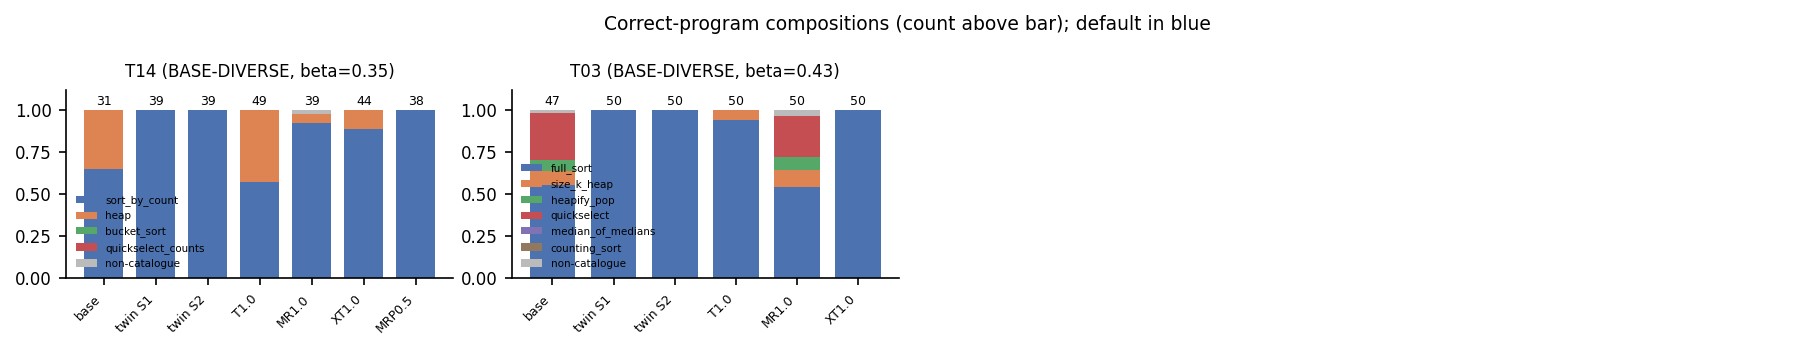

In [21]:
fig_compositions(c1, cf)

**Forest plot** (the original `fig4_forest`). Each row shows the difference in the per-slot rate of correct
off-default programs, transplant minus control, with a Newcombe 95% CI. The text on the right gives the Holm-adjusted
p of the 11-test family. On T14 every interval lies right of zero. On T03 the interval against MR lies left of zero:
the random push moves the algorithm more than the base state does.

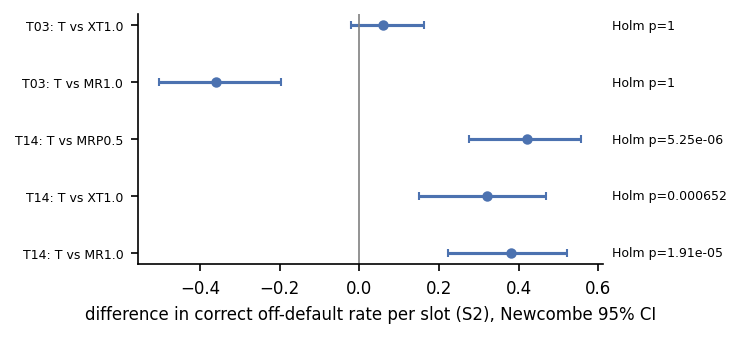

In [22]:
# the published figure shows the Holm values of the full 11-test family (Section 7)
cf_holm11 = {**cf, "per_task": {t: {**r, "holm": {k.split("|")[1]: v for k, v in holm_all.items()
                                                 if k.startswith(t + "|")}}
                                for t, r in cf["per_task"].items()}}
fig_forest(cf_holm11)

**Plan-site geometry** (the original `fig5_geometry`). Metric MDS of the actual prefill activation states at two sites:

- `S27`: the task-spec positions of block 27, just past the transplant band (blocks 12-23);
- `R23`: the read position (the last prompt token) at block 23.

The markers are:

| Marker | State |
|---|---|
| triangles (up = instruct, down = base) | centroids of "Implement X" prompts that force one algorithm |
| circles (blue = instruct, green = base) | the five twin states of each model |
| red squares | the transplanted states `T(lambda*)` |
| pink | `READ(1)` |
| grey x | the isotropic push `ISO(1)` (T03 only) |

`src/geometry5.py` computed these coordinates from the 6.5 GB activation cache. The cache is not published; the
coordinates ship in `mini_demo_data.json`. The printout under the figure says how far the transplanted centroid moved
along the instruct-to-base twin gap at each site.

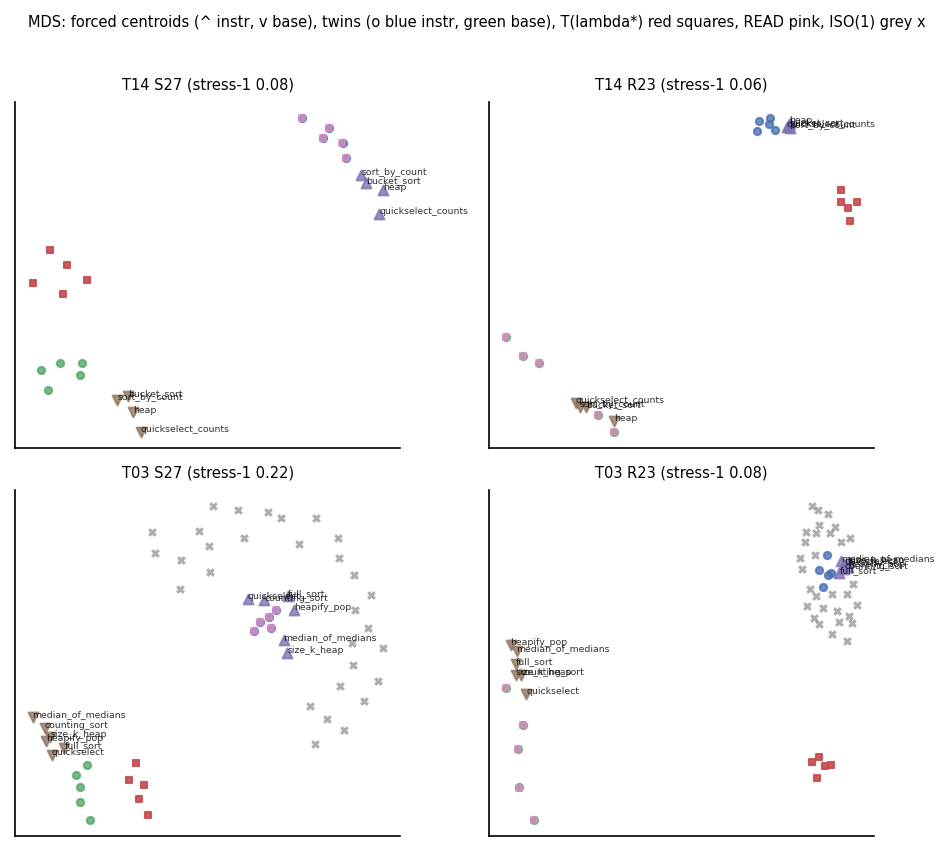

Distance of the T(lambda*) centroid from the instruct twin, as a fraction of the instruct -> base twin gap:
  T14 (lambda* = 1.0): S18 1.00, S23 1.00, S27 0.89, R18 0.18, R23 0.31
  T03 (lambda* = 1.0): S18 1.00, S23 1.00, S27 0.88, R18 0.18, R23 0.30


In [23]:
geo = data["metadata"]["geometry"]
fig_geometry({"panels": {t: geo["panels"][t] for t in TASKS}})
print("Distance of the T(lambda*) centroid from the instruct twin, as a fraction of the instruct -> base twin gap:")
for t in TASKS:
    p = geo["panels"][t]
    print(f"  {t} (lambda* = {p['lambda_star']}): "
          + ", ".join(f"{s} {v:.2f}" for s, v in p["T_frac_of_gap_from_instr_all_sites"].items()))

**The CRN pairs behind each McNemar test** (a notebook addition). Each panel is one test: rows are templates W1-W5,
columns are S2 slots. A cell is coloured by the paired outcome y (correct *and* off-default) of the transplant and the
control on that slot:

| Colour | Paired outcome |
|---|---|
| red | only the transplant is off-default (counts toward b) |
| blue | only the control is off-default (counts toward c) |
| green | both are |
| grey | neither is |

The McNemar test uses only the red and blue cells.

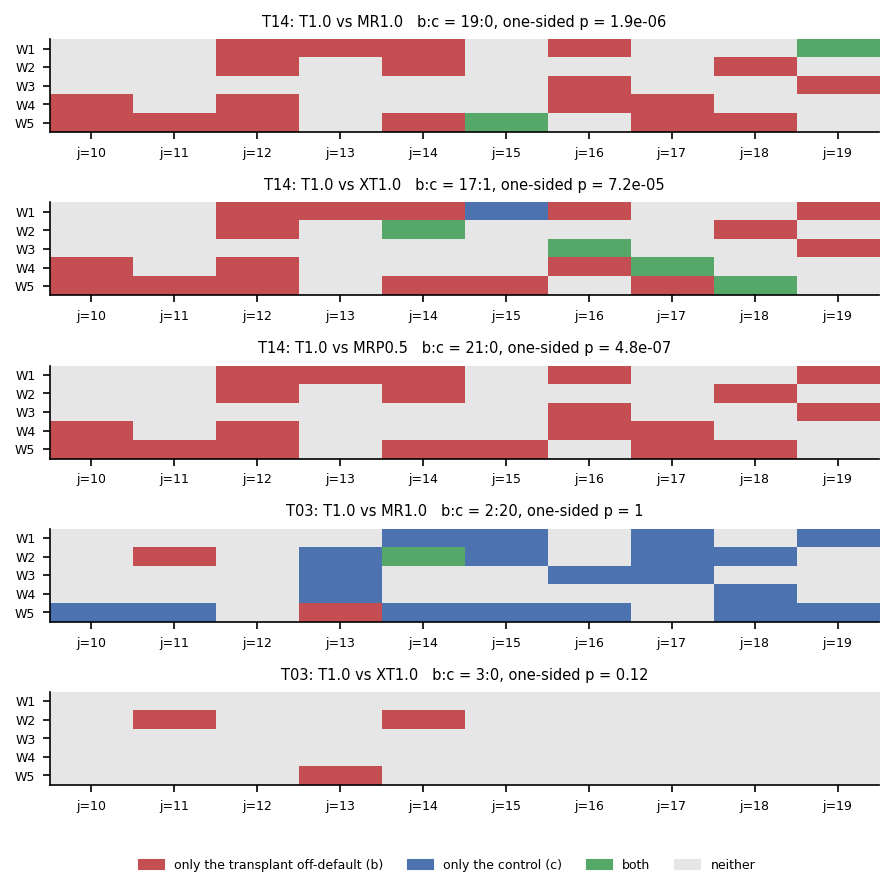

In [24]:
PAIR_C = {(1, 0): "#C44E52", (0, 1): "#4C72B0", (1, 1): "#55A868", (0, 0): "#E6E6E6"}
tests = [(t, a) for t, r in cf["per_task"].items() for a in list(r["arms"])[1:]]
fig, axes = plt.subplots(len(tests), 1, figsize=(6.0, 1.05 * len(tests) + 0.6), squeeze=False)
for ax, (t, a) in zip(axes[:, 0], tests):
    d, ct = c1["per_task"][t]["default"], catalogue(t)
    T_arm = next(iter(cf["per_task"][t]["arms"]))
    Tr = {(x["template"], int(x["slot"])): x for x in sel(labs, t, T_arm, S2_SLOTS_50)}
    Cr = {(x["template"], int(x["slot"])): x for x in sel(labs, t, a, S2_SLOTS_50)}
    img = np.ones((len(TEMPLATE_IDS), len(S2_SLOTS_50), 3))
    for i, w in enumerate(TEMPLATE_IDS):
        for j, s in enumerate(S2_SLOTS_50):
            if (w, s) in Tr and (w, s) in Cr:
                img[i, j] = to_rgb(PAIR_C[(A.y_off(Tr[(w, s)], d, ct), A.y_off(Cr[(w, s)], d, ct))])
    ax.imshow(img, aspect="auto", interpolation="nearest")
    m = cf["per_task"][t]["arms"][a]["mcnemar_T_vs_this"]
    ax.set_title(f"{t}: {T_arm} vs {a}   b:c = {m['b']}:{m['c']}, one-sided p = {m['p_one']:.2g}", fontsize=7)
    ax.set_yticks(range(len(TEMPLATE_IDS)))
    ax.set_yticklabels(TEMPLATE_IDS, fontsize=6)
    ax.set_xticks(range(len(S2_SLOTS_50)))
    ax.set_xticklabels([f"j={s}" for s in S2_SLOTS_50], fontsize=6)
fig.legend(handles=[Patch(color=PAIR_C[k], label=v) for k, v in
                    (((1, 0), "only the transplant off-default (b)"), ((0, 1), "only the control (c)"),
                     ((1, 1), "both"), ((0, 0), "neither"))],
           loc="lower center", ncol=4, fontsize=6, frameon=False)
fig.tight_layout(rect=(0, 0.05, 1, 1))
plt.show()

## Summary

At the original configuration, the replay reproduces the published Stage-4 numbers of T14 and T03 exactly.

**T14 (top-k frequent): Claim B passes on all four conditions.**

- The full transplant T(1) writes the base model's runner-up, a heap, in 21 of 49 correct programs. The twin writes
  none (0 of 39).
- The pass rate rises from 0.78 to 0.98.
- T(1) beats every control on the same CRN slots:

  | Control | McNemar b:c |
  |---|---|
  | MR(1) | 19:0 |
  | XT(1) | 17:1 |
  | MRP(0.5) | 21:0 |

**T03 (k-th smallest): Claim B fails.**

- The transplant stays on `full_sort`: 3 of 50 programs are off-default.
- The norm-matched random push moves 21 of 50 (McNemar T vs MR: 2:20).
- So the base model's states hold the default *more* firmly than random noise of the same size.

**The frozen verdict is DISCONFIRMED.** Adding the committed rules of T2, T10 and T1 (all fail condition (iii)) gives
PASS on 1 of 5 decisive tasks, against the 4 needed.

**Checks.** The independent `audit/rederive.py` code matches on every check. The arm-shuffle placebo rejects at
0.025 on these two tasks (nominal 0.05; the full run gave 0.012).

**Geometry.** At block 27 the transplanted plan state stays base-like: its centroid is 0.88-0.89 of the way along the
instruct-to-base gap. At the read position it has moved only 0.18-0.31 of the way. Later blocks pull the computation
back toward the instruct model.

**Scaling back to the full run:**

- All five decisive tasks, or the outcome-blind N = 100 extension (slots j = 10-29), need more slots than this
  100-example demo file holds. Rebuild it with `tools/build_mini_demo_data.py` from the artifact folder, then raise
  `TASKS` and `N_S2_SLOTS`.
- Stages 0-5 (the sampling and the transplant itself) need a GPU: `python method.py --stage all` in the artifact
  repository.